In [ ]:
# Question 3a - Step 1 — Importing libraries and preparing the dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

dataset = pd.read_csv("Assignment2.csv")

# Construct gross risk-free return
dataset["Rf"] = 1 + dataset["rf"]

dataset.head()

,date,dc,rmrf,smb,hml,rf,R1,R2,R3,R4,R5,R6,R7,R8,R9,R10,Rf
0,1952,1.039208,0.1180,-0.0702,0.0405,0.0166,0.1432,0.0982,0.1471,0.1852,0.1291,0.0931,0.1288,0.1617,0.0508,0.3209,1.0166
1,1953,0.996975,-0.0105,-0.0080,-0.0870,0.0182,0.0414,0.0282,-0.0124,0.0008,0.0375,-0.0207,-0.0730,-0.0280,-0.0719,-0.1455,1.0182
2,1954,1.034664,0.4935,-0.0246,0.2574,0.0086,0.5228,0.3877,0.4527,0.4116,0.5855,0.6271,0.5594,0.8194,0.6587,0.7037,1.0086
3,1955,1.033162,0.2375,-0.0676,0.0571,0.0157,0.3215,0.2087,0.2185,0.2596,0.2059,0.2475,0.1886,0.3581,0.2485,0.1853,1.0157
4,1956,1.011275,0.0590,-0.0138,-0.0107,0.0246,0.0372,0.0911,0.1006,0.1424,0.2034,0.1000,0.0962,0.0811,0.0529,-0.0093,1.0246


In [3]:
# Step 2 — Constructing the moment functions

def moment_functions(parameters):

    beta, gamma = parameters

    # Consumption-based stochastic discount factor
    m = beta * dataset["dc"] ** (-gamma)

    # First moment function: risk-free asset
    g1 = m * dataset["Rf"] - 1

    # Second moment function: market excess return
    g2 = m * dataset["rmrf"]

    return np.column_stack((g1, g2))

In [4]:
# Step 3 — Calculating the sample moments

def sample_moments(parameters):
    return moment_functions(parameters).mean(axis=0)

# Initial parameter values specified in the assignment
initial_parameters = np.array([1.0, 50.0])

# Calculate the initial sample moments
initial_moments = sample_moments(initial_parameters)

print("First sample moment:", initial_moments[0])
print("Second sample moment:", initial_moments[1])

First sample moment: -0.5521470133510532
Second sample moment: 0.013024899179436606


In [5]:
# Step 4 — Constructing the GMM objective function

weighting_matrix = np.eye(2)

def gmm_objective(parameters):
    g = sample_moments(parameters)
    return g.T @ weighting_matrix @ g

initial_objective = gmm_objective(initial_parameters)

print("Initial GMM objective:", initial_objective)

Initial GMM objective: 0.3050359723511226


In [6]:
# Step 5 — Estimating parameters using one-step GMM

results = minimize(
    gmm_objective,
    initial_parameters,
    method="Nelder-Mead",
    options={"xatol": 1e-10, "fatol": 1e-12}
)

estimated_beta, estimated_gamma = results.x

print("Convergence:", results.success)
print("Estimated beta:", estimated_beta)
print("Estimated gamma:", estimated_gamma)
print("Final GMM objective:", results.fun)
print("Final sample moments:", sample_moments(results.x))

Convergence: True
Estimated beta: 2.839811651052655
Estimated gamma: 78.30040296071607
Final GMM objective: 3.1325924544755758e-27
Final sample moments: [ 4.36229536e-14 -3.50660858e-14]


In [7]:
# Step 6 — Calculating the Jacobian matrix

dc = dataset["dc"]
Rf = dataset["Rf"]
rmrf = dataset["rmrf"]

D = np.array([
    [
        np.mean(dc ** (-estimated_gamma) * Rf),
        np.mean(-estimated_beta * dc ** (-estimated_gamma) * np.log(dc) * Rf)
    ],
    [
        np.mean(dc ** (-estimated_gamma) * rmrf),
        np.mean(-estimated_beta * dc ** (-estimated_gamma) * np.log(dc) * rmrf)
    ]
])

print("Jacobian matrix:")
print(D)

Jacobian matrix:
[[ 3.52136030e-01 -5.61257964e-03]
 [-1.23531586e-14 -9.80230199e-04]]


In [8]:
# Step 7 — Calculating the moment covariance matrix

G = moment_functions(results.x)

T = len(dataset)

S = (G.T @ G) / T

print("Moment covariance matrix:")
print(S)

Moment covariance matrix:
[[ 2.03275159 -0.16605763]
 [-0.16605763  0.23648169]]


In [9]:
# Step 8 — Calculating the GMM parameter covariance matrix

W = weighting_matrix

A = np.linalg.inv(D.T @ W @ D)

parameter_covariance = (A @ D.T @ W @ S @ W @ D @ A) / T

standard_errors = np.sqrt(np.diag(parameter_covariance))

print("Parameter covariance matrix:")
print(parameter_covariance)

print("\nStandard error of beta:", standard_errors[0])
print("Standard error of gamma:", standard_errors[1])

Parameter covariance matrix:
[[1.49607393e+00 6.99025159e+01]
 [6.99025159e+01 3.90661682e+03]]

Standard error of beta: 1.2231410104129825
Standard error of gamma: 62.50293451942264


In [10]:
# Step 9 — Calculating z-statistics and confidence intervals

from scipy.stats import norm

z_statistics = results.x / standard_errors
p_values = 2 * norm.sf(np.abs(z_statistics))

critical_value = norm.ppf(0.975)

lower_bound = results.x - critical_value * standard_errors
upper_bound = results.x + critical_value * standard_errors

inference_table = pd.DataFrame({
    "Parameter": ["Beta", "Gamma"],
    "Estimate": results.x,
    "Standard Error": standard_errors,
    "Z-statistic": z_statistics,
    "P-value": p_values,
    "95% CI Lower": lower_bound,
    "95% CI Upper": upper_bound
})

inference_table.round(4)

,Parameter,Estimate,Standard Error,Z-statistic,P-value,95% CI Lower,95% CI Upper
0,Beta,2.8398,1.2231,2.3217,0.0202,0.4425,5.2371
1,Gamma,78.3004,62.5029,1.2527,0.2103,-44.2031,200.8039


In [11]:
# Question 3b — Step 1: Constructing the moment function

def moment_function_b(parameters):

    gamma = parameters[0]

    # Normalized stochastic discount factor
    m = dataset["dc"] ** (-gamma)

    # Market excess return moment function
    g = m * dataset["rmrf"]

    return g.to_numpy()


def sample_moment_b(parameters):
    return moment_function_b(parameters).mean()


# Initial parameter value
initial_parameters_b = np.array([50.0])

print("Initial sample moment:", sample_moment_b(initial_parameters_b))

Initial sample moment: 0.013024899179436606


In [12]:
# Question 3b — Step 2: Estimating gamma using one-step GMM

def gmm_objective_b(parameters):
    g = sample_moment_b(parameters)
    return g ** 2


results_b = minimize(
    gmm_objective_b,
    initial_parameters_b,
    method="Nelder-Mead",
    options={"xatol": 1e-10, "fatol": 1e-12}
)

estimated_gamma_b = results_b.x[0]

print("Convergence:", results_b.success)
print("Estimated gamma:", estimated_gamma_b)
print("Final GMM objective:", results_b.fun)
print("Final sample moment:", sample_moment_b(results_b.x))

Convergence: True
Estimated gamma: 78.30040296066727
Final GMM objective: 2.02027877398353e-29
Final sample moment: 4.494751132135716e-15


In [13]:
# Question 3b — Step 3: Statistical inference

# Jacobian
D_b = np.mean(
    -dc ** (-estimated_gamma_b) * np.log(dc) * rmrf
)

# Moment variance
G_b = moment_function_b(results_b.x)
S_b = np.mean(G_b ** 2)

# Parameter variance and standard error
variance_b = S_b / (T * D_b ** 2)
standard_error_b = np.sqrt(variance_b)

# Statistical inference
z_statistic_b = estimated_gamma_b / standard_error_b
p_value_b = 2 * norm.sf(abs(z_statistic_b))

lower_bound_b = estimated_gamma_b - critical_value * standard_error_b
upper_bound_b = estimated_gamma_b + critical_value * standard_error_b

inference_table_b = pd.DataFrame({
    "Parameter": ["Gamma"],
    "Estimate": [estimated_gamma_b],
    "Standard Error": [standard_error_b],
    "Z-statistic": [z_statistic_b],
    "P-value": [p_value_b],
    "95% CI Lower": [lower_bound_b],
    "95% CI Upper": [upper_bound_b]
})

inference_table_b.round(4)

,Parameter,Estimate,Standard Error,Z-statistic,P-value,95% CI Lower,95% CI Upper
0,Gamma,78.3004,62.5029,1.2527,0.2103,-44.2031,200.8039


In [14]:
# Question 3c — Step 1: Constructing excess returns

portfolio_columns = [f"R{i}" for i in range(1, 11)]

# Calculate excess returns for the ten portfolios
portfolio_excess_returns = dataset[portfolio_columns].sub(
    dataset["rf"], axis=0
)

portfolio_excess_returns.columns = [
    f"R{i}e" for i in range(1, 11)
]

# Combine portfolio excess returns and factor returns
excess_returns_c = pd.concat(
    [portfolio_excess_returns, dataset[["rmrf", "smb", "hml"]]],
    axis=1
)

print("Dimensions:", excess_returns_c.shape)
print("Missing values:", excess_returns_c.isna().sum().sum())

excess_returns_c.head()

Dimensions: (63, 13)
Missing values: 0


,R1e,R2e,R3e,R4e,R5e,R6e,R7e,R8e,R9e,R10e,rmrf,smb,hml
0,0.1266,0.0816,0.1305,0.1686,0.1125,0.0765,0.1122,0.1451,0.0342,0.3043,0.1180,-0.0702,0.0405
1,0.0232,0.0100,-0.0306,-0.0174,0.0193,-0.0389,-0.0912,-0.0462,-0.0901,-0.1637,-0.0105,-0.0080,-0.0870
2,0.5142,0.3791,0.4441,0.4030,0.5769,0.6185,0.5508,0.8108,0.6501,0.6951,0.4935,-0.0246,0.2574
3,0.3058,0.1930,0.2028,0.2439,0.1902,0.2318,0.1729,0.3424,0.2328,0.1696,0.2375,-0.0676,0.0571
4,0.0126,0.0665,0.0760,0.1178,0.1788,0.0754,0.0716,0.0565,0.0283,-0.0339,0.0590,-0.0138,-0.0107


In [15]:
# Question 3c — Step 2: Constructing the 13 moment functions

def moment_functions_c(parameters):

    gamma = parameters[0]

    # Normalized stochastic discount factor
    m = dataset["dc"] ** (-gamma)

    # Multiply each excess return series by the SDF
    G = excess_returns_c.mul(m, axis=0)

    return G.to_numpy()


def sample_moments_c(parameters):
    return moment_functions_c(parameters).mean(axis=0)


initial_parameters_c = np.array([50.0])

initial_moments_c = pd.Series(
    sample_moments_c(initial_parameters_c),
    index=excess_returns_c.columns
)

print("Initial sample moments:")
print(initial_moments_c.round(6))

Initial sample moments:
R1e     0.014966
R2e     0.015184
R3e     0.015964
R4e     0.015096
R5e     0.018407
R6e     0.017667
R7e     0.010135
R8e     0.014760
R9e     0.027891
R10e    0.017449
rmrf    0.013025
smb     0.010810
hml     0.009086
dtype: float64


In [16]:
# Question 3c — Step 3: Estimating gamma using 13 moment conditions

weighting_matrix_c = np.eye(13)

def gmm_objective_c(parameters):
    g = sample_moments_c(parameters)
    return g.T @ weighting_matrix_c @ g

results_c = minimize(
    gmm_objective_c,
    initial_parameters_c,
    method="Nelder-Mead",
    options={"xatol": 1e-10, "fatol": 1e-12}
)

estimated_gamma_c = results_c.x[0]

print("Convergence:", results_c.success)
print("Estimated gamma:", estimated_gamma_c)
print("Initial GMM objective:", gmm_objective_c(initial_parameters_c))
print("Final GMM objective:", results_c.fun)

print("\nFinal sample moments:")
print(pd.Series(
    sample_moments_c(results_c.x),
    index=excess_returns_c.columns
).round(6))

Convergence: True
Estimated gamma: 80.75443593799719
Initial GMM objective: 0.003360209912794546
Final GMM objective: 0.0003284369481449345

Final sample moments:
R1e     0.003899
R2e     0.002315
R3e     0.002659
R4e     0.000049
R5e     0.003447
R6e     0.001159
R7e    -0.006720
R8e    -0.006051
R9e     0.009610
R10e   -0.004561
rmrf   -0.000830
smb     0.009354
hml     0.002111
dtype: float64


In [17]:
# Question 3c — Step 4: Statistical inference

# Jacobian matrix
derivative_c = -dc ** (-estimated_gamma_c) * np.log(dc)

D_c = excess_returns_c.mul(
    derivative_c, axis=0
).mean().to_numpy().reshape(13, 1)

# Moment covariance matrix
G_c = moment_functions_c(results_c.x)
S_c = (G_c.T @ G_c) / T

# GMM parameter covariance matrix
W_c = weighting_matrix_c

A_c = np.linalg.inv(D_c.T @ W_c @ D_c)

parameter_covariance_c = (
    A_c @ D_c.T @ W_c @ S_c @ W_c @ D_c @ A_c
) / T

standard_error_c = np.sqrt(parameter_covariance_c[0, 0])

# Statistical inference
z_statistic_c = estimated_gamma_c / standard_error_c
p_value_c = 2 * norm.sf(abs(z_statistic_c))

lower_bound_c = estimated_gamma_c - critical_value * standard_error_c
upper_bound_c = estimated_gamma_c + critical_value * standard_error_c

inference_table_c = pd.DataFrame({
    "Parameter": ["Gamma"],
    "Estimate": [estimated_gamma_c],
    "Standard Error": [standard_error_c],
    "Z-statistic": [z_statistic_c],
    "P-value": [p_value_c],
    "95% CI Lower": [lower_bound_c],
    "95% CI Upper": [upper_bound_c]
})

inference_table_c.round(4)

,Parameter,Estimate,Standard Error,Z-statistic,P-value,95% CI Lower,95% CI Upper
0,Gamma,80.7544,53.2725,1.5159,0.1296,-23.6577,185.1665


In [18]:
# Question 3d — Step 1: Constructing the stochastic discount factor

m_c = dataset["dc"] ** (-estimated_gamma_c)

print("Number of observations:", len(m_c))
print("Mean SDF:", m_c.mean())
print("Minimum SDF:", m_c.min())
print("Maximum SDF:", m_c.max())

Number of observations: 63
Mean SDF: 0.33290671283138473
Minimum SDF: 0.01123902506705493
Maximum SDF: 2.4739004797879627


In [19]:
# Question 3d — Step 2: Calculating actual and predicted returns

# Historical mean excess returns
actual_returns_c = excess_returns_c.mean()

# Covariances between SDF and excess returns
covariances_c = excess_returns_c.apply(
    lambda returns: returns.cov(m_c)
)

# Model-predicted expected excess returns
predicted_returns_c = -covariances_c / m_c.mean()

# Construct the results table
pricing_table_c = pd.DataFrame({
    "Mean": actual_returns_c,
    "Covariance with SDF": covariances_c,
    "Predicted Return": predicted_returns_c
})

pricing_table_c.loc["m"] = [m_c.mean(), np.nan, np.nan]

# Place the SDF first, followed by factors and portfolios
pricing_table_c = pricing_table_c.loc[
    ["m", "rmrf", "smb", "hml"] +
    [f"R{i}e" for i in range(1, 11)]
]

pricing_table_c.round(4)

,Mean,Covariance with SDF,Predicted Return
m,0.3329,NaN,NaN
rmrf,0.0787,-0.0275,0.0825
smb,0.0264,0.0006,-0.0017
hml,0.0491,-0.0145,0.0435
R1e,0.0706,-0.0199,0.0598
R2e,0.0771,-0.0237,0.0713
R3e,0.0800,-0.0243,0.0731
R4e,0.0816,-0.0275,0.0827
R5e,0.0874,-0.0260,0.0782
R6e,0.0973,-0.0317,0.0953


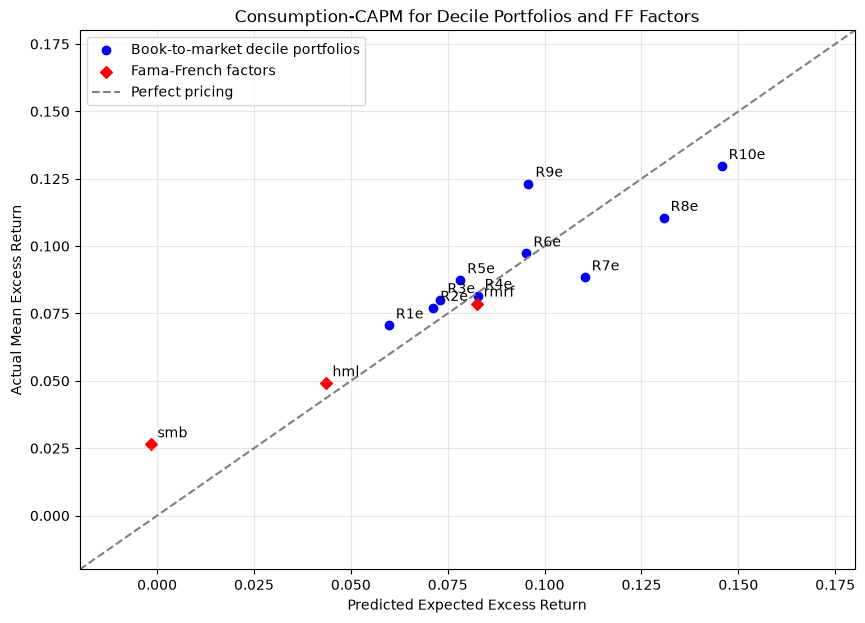

In [20]:
# Question 3e — Plotting predicted versus actual excess returns

plt.figure(figsize=(10, 7))

# Plot the ten decile portfolios
plt.scatter(
    predicted_returns_c[portfolio_excess_returns.columns],
    actual_returns_c[portfolio_excess_returns.columns],
    color="blue",
    label="Book-to-market decile portfolios"
)

# Plot the three Fama-French factors
factors = ["rmrf", "smb", "hml"]

plt.scatter(
    predicted_returns_c[factors],
    actual_returns_c[factors],
    color="red",
    marker="D",
    label="Fama-French factors"
)

# Label each observation
for asset in excess_returns_c.columns:
    plt.annotate(
        asset,
        (predicted_returns_c[asset], actual_returns_c[asset]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Perfect pricing reference line
plt.plot(
    [-0.02, 0.18], [-0.02, 0.18],
    linestyle="--",
    color="gray",
    label="Perfect pricing"
)

plt.xlabel("Predicted Expected Excess Return")
plt.ylabel("Actual Mean Excess Return")
plt.title("Consumption-CAPM for Decile Portfolios and FF Factors")

plt.xlim(-0.02, 0.18)
plt.ylim(-0.02, 0.18)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
# Question 3f — Step 1: Constructing the linear GMM model

factor_returns_f = dataset[["rmrf", "smb", "hml"]].to_numpy()
test_returns_f = portfolio_excess_returns.to_numpy()

# Mean portfolio excess returns
y_f = test_returns_f.mean(axis=0)

# Mean products of portfolio excess returns and factors
X_f = (test_returns_f.T @ factor_returns_f) / T

print("Dimensions of y:", y_f.shape)
print("Dimensions of X:", X_f.shape)

pd.DataFrame(
    X_f,
    index=portfolio_excess_returns.columns,
    columns=["rmrf", "smb", "hml"]
).round(6)

Dimensions of y: (10,)
Dimensions of X: (10, 3)


,rmrf,smb,hml
R1e,0.041319,0.006132,-0.007061
R2e,0.036791,0.006160,-0.000243
R3e,0.036904,0.007334,0.002024
R4e,0.035711,0.008951,0.004724
R5e,0.037175,0.008744,0.005784
R6e,0.035649,0.008301,0.009147
R7e,0.038827,0.010608,0.009924
R8e,0.042427,0.011382,0.013897
R9e,0.043979,0.014298,0.013513
R10e,0.048943,0.016004,0.016762


In [22]:
# Question 3f — Step 2: Estimating the GMM coefficients

weighting_matrix_f = np.eye(10)

estimated_parameters_f = np.linalg.lstsq(
    X_f, y_f, rcond=None
)[0]

estimated_a, estimated_b, estimated_c = estimated_parameters_f

# Final sample moments
final_moments_f = y_f - X_f @ estimated_parameters_f

# Minimized GMM objective
final_objective_f = (
    final_moments_f.T @ weighting_matrix_f @ final_moments_f
)

print("Estimated a:", estimated_a)
print("Estimated b:", estimated_b)
print("Estimated c:", estimated_c)
print("Final GMM objective:", final_objective_f)
print("Matrix rank:", np.linalg.matrix_rank(X_f))

Estimated a: 2.0677264793055414
Estimated b: -0.07032696665869964
Estimated c: 1.8930576671293544
Final GMM objective: 0.0002210069072758373
Matrix rank: 3


In [23]:
# Question 3f — Step 3: Statistical inference

# Jacobian matrix
D_f = -X_f

# Fama-French stochastic discount factor
m_f = 1 - factor_returns_f @ estimated_parameters_f

# Individual moment functions
G_f = m_f[:, None] * test_returns_f

# Moment covariance matrix
S_f = (G_f.T @ G_f) / T

# GMM parameter covariance matrix
W_f = weighting_matrix_f

A_f = np.linalg.inv(D_f.T @ W_f @ D_f)

parameter_covariance_f = (
    A_f @ D_f.T @ W_f @ S_f @ W_f @ D_f @ A_f
) / T

# Statistical inference
standard_errors_f = np.sqrt(np.diag(parameter_covariance_f))

z_statistics_f = estimated_parameters_f / standard_errors_f

p_values_f = 2 * norm.sf(np.abs(z_statistics_f))

inference_table_f = pd.DataFrame({
    "Parameter": ["a", "b", "c"],
    "Coefficient": estimated_parameters_f,
    "Standard Error": standard_errors_f,
    "Z-statistic": z_statistics_f,
    "P-value": p_values_f
})

inference_table_f.round(4)

,Parameter,Coefficient,Standard Error,Z-statistic,P-value
0,a,2.0677,0.6871,3.0092,0.0026
1,b,-0.0703,2.1507,-0.0327,0.9739
2,c,1.8931,1.0124,1.8698,0.0615


In [24]:
# Question 3g — Examining SDF positivity

m2 = m_f.copy()

print("Mean SDF:", m2.mean())
print("Minimum SDF:", m2.min())
print("Maximum SDF:", m2.max())
print("Negative observations:", np.sum(m2 < 0))

Mean SDF: 0.7461857750554574
Minimum SDF: -0.5094261044361845
Maximum SDF: 1.7788150129113665
Negative observations: 2


In [25]:
# Question 3h — Calculating means and covariances

# Convert SDF into a pandas Series
m2_series = pd.Series(m2, index=dataset.index)

# Historical mean excess returns
actual_returns_f = portfolio_excess_returns.mean()

# Covariances between SDF and excess returns
covariances_f = portfolio_excess_returns.apply(
    lambda returns: returns.cov(m2_series)
)

# Construct the results table
pricing_table_f = pd.DataFrame({
    "Mean": actual_returns_f,
    "Covariance with SDF": covariances_f
})

pricing_table_f.loc["m2"] = [m2_series.mean(), np.nan]

# Reorder the table
pricing_table_f = pricing_table_f.loc[
    ["m2"] + list(portfolio_excess_returns.columns)
]

pricing_table_f.round(4)

,Mean,Covariance with SDF
m2,0.7462,NaN
R1e,0.0706,-0.0546
R2e,0.0771,-0.0565
R3e,0.0800,-0.0603
R4e,0.0816,-0.0624
R5e,0.0874,-0.0661
R6e,0.0973,-0.0668
R7e,0.0884,-0.0771
R8e,0.1105,-0.0866
R9e,0.1232,-0.0856


In [29]:
# Question 3i — Step 1: Calculating predicted excess returns

predicted_returns_f = -covariances_f / m2_series.mean()

final_table_f = pd.DataFrame({
    "Actual Return": actual_returns_f,
    "Predicted Return (GMM)": predicted_returns_f
})

final_table_f.map(lambda x: f"{x:.2%}")

,Actual Return,Predicted Return (GMM)
R1e,7.06%,7.32%
R2e,7.71%,7.57%
R3e,8.00%,8.08%
R4e,8.16%,8.37%
R5e,8.74%,8.86%
R6e,9.73%,8.95%
R7e,8.84%,10.33%
R8e,11.05%,11.60%
R9e,12.32%,11.47%
R10e,12.97%,13.47%


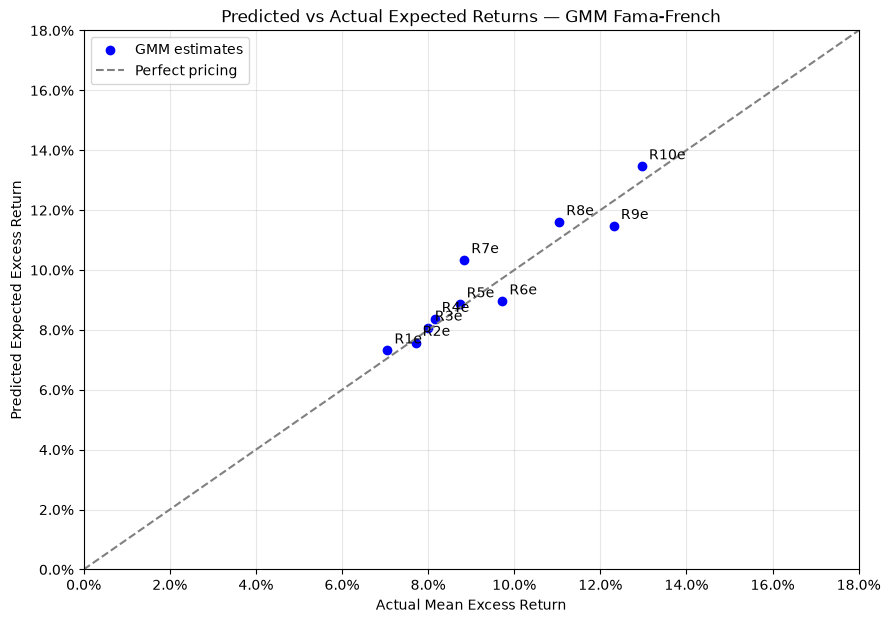

In [30]:
# Question 3i — Step 2: Plotting predicted versus actual returns

from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(10, 7))

plt.scatter(
    actual_returns_f,
    predicted_returns_f,
    color="blue",
    label="GMM estimates"
)

# Label each portfolio
for asset in actual_returns_f.index:
    plt.annotate(
        asset,
        (actual_returns_f[asset], predicted_returns_f[asset]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Perfect pricing reference line
plt.plot(
    [0, 0.18], [0, 0.18],
    linestyle="--",
    color="gray",
    label="Perfect pricing"
)

plt.xlabel("Actual Mean Excess Return")
plt.ylabel("Predicted Expected Excess Return")
plt.title("Predicted vs Actual Expected Returns — GMM Fama-French")

plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))

plt.xlim(0, 0.18)
plt.ylim(0, 0.18)

plt.legend()
plt.grid(alpha=0.3)
plt.show()